<a href="https://colab.research.google.com/github/loginyrlife/ai_learning/blob/main/CIFAR10_CNN_%EC%8B%A4%EC%8A%B5_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-10 CNN 실습
간단한 CNN(**Conv 3층 + FC**)을 베이스라인으로 제공합니다.
여러분의 목표는 무엇이든 활용해 정확도를 올리는 것 입니다.

**진행 순서**
1. 학습 함수 `train()` · 평가 함수 `evaluate()`
2. 데이터 불러오기 (Train / Valid / Test)
3. 베이스라인 모델 정의
4. 베이스라인 학습 & 단일 평가
5. 나만의 모델 만들기

> Colab에서는 **런타임 → 런타임 유형 변경 → GPU** 를 켜고 실행하세요.

In [ ]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

In [ ]:
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 10
print("device:", device)

device: cuda


## 1) Train / Evaluate 함수
실험에 쓸 함수를 먼저 만들어 둡니다. 여기서는 **정의만** 하고, 실제 사용은 4) ,5) 에서 하게 될 예정입니다.

- 함수 안에 나오는 `val_loader`, `test_loader`, `train_tf` 등은  2)에서 다뤄지니 그쪽을 참고해 주세요.
<br>


### `train(model, name, epochs, lr, weight_decay, transform)`
: 모델을 학습시키고, epoch마다 Valid 정확도를 출력합니다.
  - `weight_decay` 는 L2 규제 세기입니다 (default = 0).
  - `transform` 은 이 모델의 **학습 데이터 전처리**입니다. 모델마다 다른 데이터 증강을 줄 수 있습니다.
<br>


 ### `evaluate(...)`
: 학습이 끝난 모델을 **Test 데이터로** 평가합니다.
  - `evaluate(model)` → 모델 **하나**의 상세 평가 (정확도, 학습 곡선, 클래스별 정확도)
  - `evaluate([model1, model2, ...])` → 여러 모델을 함께 비교

<br>

> 함수 내부를 전부 이해하지 않아도 괜찮습니다. 어떤 식으로 동작하는지 흐름 정도만 파악하고 넘어가세요.

> 평가 함수 셀은 그렇게 중요하진 않은 내용이라 코드를 접어뒀습니다. 실행은 그대로 하면 되고, 코드 전체는 셀 제목을 클릭하거나 `코드 표시`를 눌러 확인 하실 수 있으십니다.

In [ ]:
def run_epoch(model, loader, optimizer=None):
    # optimizer가 있으면 학습, 없으면 평가만.
    training = optimizer is not None
    model.train(training)
    total_loss, correct = 0.0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader: #데이터 문제(x), 정답-label(y)을 가져 옵니다.
            x, y = x.to(device), y.to(device)
            y_pred = model(x)                     # forward : x를 이용해 정답을 예측
            loss = F.cross_entropy(y_pred, y)     # loss 계산: 얼마나 y_pred가 실제 정답(y)와 다른지 채점

            if training:                          # train 일때만 실행
                optimizer.zero_grad()             # 이전 배치에서 계산된 기울기를 0으로 초기화
                loss.backward()                   # loss를 각 가중치(w)로 미분한 기울기를 계산.
                optimizer.step()                  # 가중치 w를 update (w_new ← w_old − lr × gradient)
            total_loss += loss.item() * len(y)
            correct += (y_pred.argmax(1) == y).sum().item()

    n = len(loader.dataset)
    return total_loss / n, correct / n
                                # ret : 평균 loss, 정확도

In [ ]:
def train(model, name="model", epochs=EPOCHS, lr=1e-3, weight_decay=0, transform=None):
    if transform is None: # transform: 이 모델의 학습 데이터에 쓸 전처리 (생략하면 기본 train_tf)
        transform = train_tf

    train_data = Subset(datasets.CIFAR10("./data", train=True, transform=transform), idx[:45000])
    loader = DataLoader(train_data, batch_size=128, shuffle=True)

    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    model.name = name
    model.history = {"train_acc": [], "val_acc": []}   # 학습 곡선 기록용

    print(f"[{name}] 학습 시작")
    start = time.time()

    for epoch in range(1, epochs + 1):
        _, train_acc = run_epoch(model, loader, optimizer)
        _, val_acc   = run_epoch(model, val_loader)
        model.history["train_acc"].append(train_acc)
        model.history["val_acc"].append(val_acc)
        print(f"  epoch {epoch:2d}: train acc = {train_acc:.2%} | val acc = {val_acc:.2%}")

    model.train_time = time.time() - start
    print(f"  → 학습 완료 ({model.train_time:.0f}초)")
    return model

In [ ]:
#@title 평가 함수 evaluate()
@torch.no_grad()
def class_accuracy(model):
    # 클래스별 테스트 정확도
    model.eval()
    correct, total = torch.zeros(10), torch.zeros(10)
    for x, y in test_loader:
        pred = model(x.to(device)).argmax(1).cpu()
        for c in range(10):
            correct[c] += ((pred == y) & (y == c)).sum()
            total[c]   += (y == c).sum()
    return (correct / total).tolist()


def summarize(model):
    # 모델 하나의 핵심 지표를 dict로 정리
    test_loss, test_acc = run_epoch(model, test_loader)
    h = model.history
    return {
        "모델": model.name,
        "파라미터 수": sum(p.numel() for p in model.parameters()),
        "Train 정확도": h["train_acc"][-1],
        "Valid 정확도": h["val_acc"][-1],
        "Test 정확도": test_acc,
        "Test Loss": test_loss,
        "과적합 정도 (Train-Test)": h["train_acc"][-1] - test_acc,
        "학습 시간(초)": model.train_time,
    }


def evaluate(models):
    # 모델 하나만 넣을 경우
    if not isinstance(models, (list, tuple)):
        model = models
        r = summarize(model)
        print(f"[{r['모델']}] 단일 평가")
        print(f"  파라미터 수     : {r['파라미터 수']:,}")
        print(f"  Train 정확도    : {r['Train 정확도']:.2%}")
        print(f"  Valid 정확도    : {r['Valid 정확도']:.2%}")
        print(f"  Test  정확도    : {r['Test 정확도']:.2%}")
        print(f"  과적합 정도     : {r['과적합 정도 (Train-Test)']:.2%}p  (Train - Test, 클수록 과적합)")
        print(f"  학습 시간       : {r['학습 시간(초)']:.0f}초")

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
        epochs = range(1, len(model.history["train_acc"]) + 1)
        ax1.plot(epochs, model.history["train_acc"], "o-", label="train")
        ax1.plot(epochs, model.history["val_acc"],   "o-", label="valid")
        ax1.set_title("Learning curve")
        ax1.set_xlabel("epoch"); ax1.set_ylabel("accuracy"); ax1.legend()

        accs = class_accuracy(model)
        ax2.bar(CLASSES, accs, color="#4472C4")
        ax2.axhline(r["Test 정확도"], color="gray", ls="--", label="overall")
        ax2.set_title("Test accuracy per class")
        ax2.set_ylim(0, 1); ax2.tick_params(axis="x", rotation=45); ax2.legend()
        plt.tight_layout()
        plt.show()
        return

    # 모델 리스트
    table = pd.DataFrame([summarize(m) for m in models]).set_index("모델")
    for col in ["Train 정확도", "Valid 정확도", "Test 정확도", "과적합 정도 (Train-Test)"]:
        table[col] = table[col].map("{:.2%}".format)
    table["Test Loss"] = table["Test Loss"].map("{:.3f}".format)
    table["파라미터 수"] = table["파라미터 수"].map("{:,}".format)
    table["학습 시간(초)"] = table["학습 시간(초)"].map("{:.0f}".format)
    display(table)

    plt.figure(figsize=(7, 4))
    for m in models:
        plt.plot(range(1, len(m.history["val_acc"]) + 1), m.history["val_acc"], "o-", label=m.name)
    plt.title("Validation accuracy")
    plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend()
    plt.show()

## 2) Data Load — Train / Valid / Test 분리
CIFAR-10: **32×32 컬러 이미지(3채널)**, 10개 클래스, 학습 50,000장 / 테스트 10,000장
- **Train (45,000)**: 가중치 학습
- **Valid (5,000)**: 학습 중 성능 확인, 하이퍼파라미터 · epoch 선택
- **Test (10,000)**: 학습이 모두 끝난 뒤 **한 번만** 평가

`train_tf` 와 `test_tf` 를 따로 둔 이유: **데이터 증강은 학습 데이터에만** 적용해야 하기 때문입니다.
여기의 `train_tf` 는 **베이스라인용 기본 전처리**입니다. 내 모델의 전처리는 ⑤ 에서 `train(..., transform=...)` 으로 따로 넘깁니다.

In [ ]:
MEAN = (0.4914, 0.4822, 0.4465)   # CIFAR-10 채널별(R, G, B) 평균
STD  = (0.2470, 0.2435, 0.2616)   # CIFAR-10 채널별(R, G, B) 표준편차

# 학습용 기본 전처리 (베이스라인용)
train_tf = transforms.Compose([
    transforms.ToTensor(),                 # 0~255 → 0~1 텐서
    transforms.Normalize(MEAN, STD),       # 채널별 정규화
])

# 검증 · 테스트용 전처리
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

* CIFAR-10 데이터셋은 원래 제공 서버(https://www.cs.toronto.edu/~kriz/cifar.html)에서 다운로드됩니다.
* 학교 네트워크 환경에서 약 27분 정도 소요되어, 미리 시냅스 구글 드라이브에 다운로드 해놓고, 해당 드라이브를 통해 데이터셋을 받아오게 해두었습니다. (약 10초 소요)
* 코드를 펼쳐보실 필요는 없고, 실행하시고, 다운로드 됐는지 확인하시면 됩니다.

In [ ]:
#@title CIFAR-10 다운로드
import os, gdown

DRIVE_FILE_ID = "1kSV-qrFTwI2Niv-7GpUoHbXY1Sn1dMOT"   # 공유된 cifar-10-python.tar.gz 의 Google Drive 파일 ID (비워두면 원래 서버에서 다운로드)

path = "./data/cifar-10-python.tar.gz"
os.makedirs("./data", exist_ok=True)
if DRIVE_FILE_ID and not os.path.exists(path):
    gdown.download(id=DRIVE_FILE_ID, output=path, quiet=False)
# 파일이 이미 있으면 아래 datasets.CIFAR10(download=True)는 다운로드를 건너뛰고 압축만 풉니다

Downloading...
From (original): https://drive.google.com/uc?id=1kSV-qrFTwI2Niv-7GpUoHbXY1Sn1dMOT
From (redirected): https://drive.google.com/uc?id=1kSV-qrFTwI2Niv-7GpUoHbXY1Sn1dMOT&confirm=t&uuid=93b2bd2e-a7ae-481b-b6de-01c1e0b0077c
To: /content/data/cifar-10-python.tar.gz
100%|██████████| 170M/170M [00:03<00:00, 55.1MB/s]


In [ ]:
train_full = datasets.CIFAR10("./data", train=True,  download=True, transform=train_tf)  # 50,000장
val_full   = datasets.CIFAR10("./data", train=True,  download=True, transform=test_tf)   # 같은 50,000장 (전처리만 다름)
test_set   = datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)   # 10,000장

# 50,000장을 섞어서 Train 45,000 / Valid 5,000 으로 나눔 (seed 고정 → 매번 같은 분할)
idx = torch.randperm(50000, generator=torch.Generator().manual_seed(42))
train_set = Subset(train_full, idx[:45000])
val_set   = Subset(val_full,   idx[45000:])

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=1000)
test_loader  = DataLoader(test_set,  batch_size=1000)

CLASSES = test_set.classes
print("클래스:", CLASSES)

클래스: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
print(f"{'split':<6} | {'images':>8} | {'batch':>6} | {'batches':>7}")
print("-" * 38)
for name, ds, loader in [("Train", train_set, train_loader),
                         ("Valid", val_set,   val_loader),
                         ("Test",  test_set,  test_loader)]:
    print(f"{name:<6} | {len(ds):>8,} | {loader.batch_size:>6} | {len(loader):>7}")

split  |   images |  batch | batches
--------------------------------------
Train  |   45,000 |    128 |     352
Valid  |    5,000 |   1000 |       5
Test   |   10,000 |   1000 |      10


### 데이터 포맷 확인
배치 하나를 꺼내서 shape과 실제 이미지를 확인합니다.

In [ ]:
x, y = next(iter(train_loader))
print(f"이미지 배치 x : {tuple(x.shape)}   ← (N, C, H, W) = (배치, 채널 3, 세로 32, 가로 32)")
print(f"정답 배치 y   : {tuple(y.shape)}")
print(f"라벨 예시     : {[CLASSES[i] for i in y[:8]]}")

이미지 배치 x : (128, 3, 32, 32)   ← (N, C, H, W) = (배치, 채널 3, 세로 32, 가로 32)
정답 배치 y   : (128,)
라벨 예시     : ['cat', 'frog', 'automobile', 'dog', 'frog', 'automobile', 'truck', 'frog']


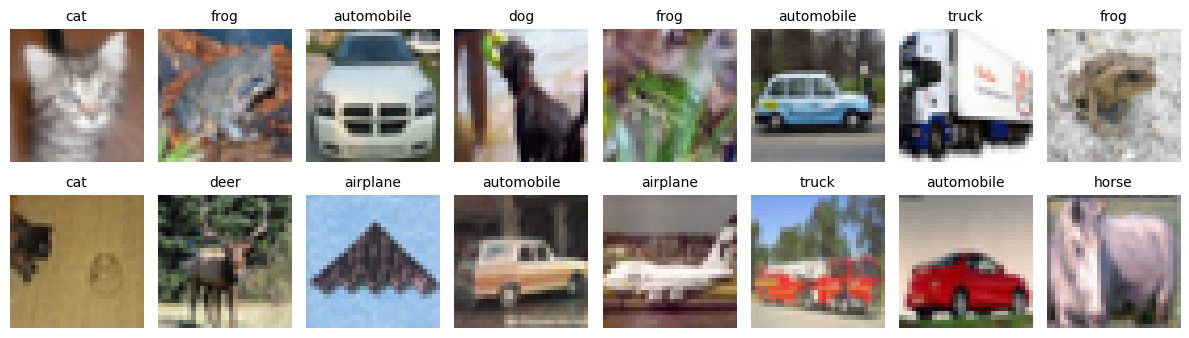

In [ ]:
def show(img):
    # 정규화된 텐서 → 원래 색으로 되돌려서 (H, W, C) 모양으로
    img = img * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    return img.permute(1, 2, 0).clamp(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.6))
for ax, img, label in zip(axes.flat, x, y):
    ax.imshow(show(img))
    ax.set_title(CLASSES[label], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3) Baseline Model — Conv 3층 + FC
- `Conv → ReLU → MaxPool` 블록을 3번 쌓고, 마지막에 FC(Linear)로 10개 클래스별로 점수를 냅니다.
- 구조 흐름이랑 아래 베이스라인 코드 부분이랑 같이 보시면, 대응되는 것을 보실 수 있습니다.


** 보통은 클래스 형식으로 모델을 많이 정의하지만 보시기에 편하시라고, 함수형으로 정의했습니다. 따라서, make_를 앞에 붙이게 되었으나, 접두사를 제외하셔도 큰 문제는 없습니다.

<table>
<tr>
<td width="68%" valign="middle">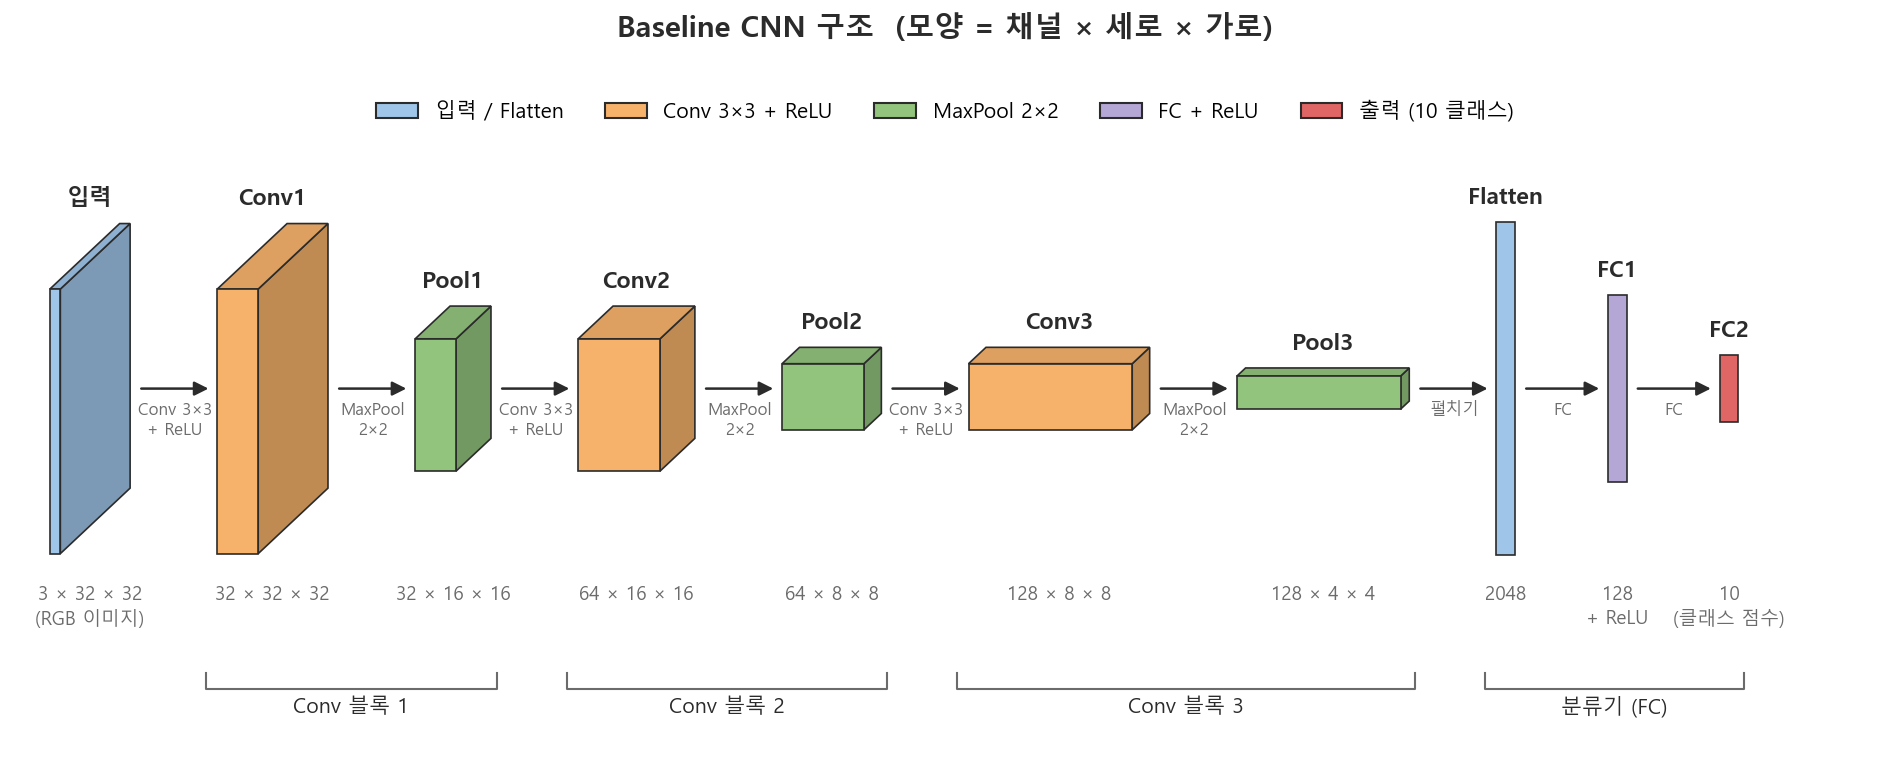</td>
<td width="32%" valign="middle">
<table>
<tr><th>단계</th><th>출력 모양</th></tr>
<tr><td>입력</td><td>(N, 3, 32, 32)</td></tr>
<tr><td>Conv 블록 1</td><td>(N, 32, 16, 16)</td></tr>
<tr><td>Conv 블록 2</td><td>(N, 64, 8, 8)</td></tr>
<tr><td>Conv 블록 3</td><td>(N, 128, 4, 4)</td></tr>
<tr><td>Flatten</td><td>(N, 2048)</td></tr>
<tr><td>FC → FC</td><td>(N, 128) → (N, 10)</td></tr>
</table>
</td>
</tr>
</table>

In [ ]:
def make_baseline():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),   # (N, 32, 16, 16)
        nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # (N, 64, 8, 8)
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # (N, 128, 4, 4)
        nn.Flatten(),                                                   # (N, 2048)
        nn.Linear(128 * 4 * 4, 128), nn.ReLU(),                         # (N, 128)
        nn.Linear(128, 10),                                             # (N, 10)  클래스 10개의 점수
    )

baseline = make_baseline()
print("출력 모양:", tuple(baseline(x).shape)) # (N, 10)  클래스 10개의 점수
print(f"파라미터 수: {sum(p.numel() for p in baseline.parameters()):,}")

출력 모양: (128, 10)
파라미터 수: 356,810


## 4) 베이스라인 학습 & 단일 평가

1)에서 정의한 `train`과 `evaluate`로 모델을 학습하고 평가합니다.

---

### `train(model, name, epochs, lr, weight_decay, transform)`
: 모델을 학습시키고, epoch마다 Valid 정확도를 출력합니다.

| 인자 | 의미 | 기본값 |
|---|---|---|
| `model` | 학습할 모델 **(필수)** | — |
| `name` | 로그 · 비교 표에 표시될 이름 | `"model"` |
| `epochs` | 전체 데이터를 몇 번 반복해서 학습할지 | `EPOCHS` (10) |
| `lr` | 학습률 (한 번에 가중치를 얼마나 크게 수정할지) | `1e-3` |
| `weight_decay` | L2 규제 세기 (0 = 규제 없음) | `0` |
| `transform` | 학습 데이터 전처리 · 증강 | `None` → 2)의 `train_tf` |

<br>

- `model` 뒤의 인자는 **생략하면 기본값**으로 학습됩니다.
- 다만 많은 모델을 한번에 평가하기 위해서, 학습시 `name` 을 꼭 입력해주시는 것을 추천합니다.  

<br>


 ### `evaluate(...)`
: 학습이 끝난 모델을 **Test 데이터로** 평가합니다.
  - `evaluate(model)` → 모델 **하나**의 상세 평가 (정확도, 학습 곡선, 클래스별 정확도)
  - `evaluate([model1, model2, ...])` → 여러 모델을 함께 비교


In [ ]:
baseline = train(make_baseline(), name="Baseline")

[Baseline] 학습 시작
  epoch  1: train acc = 47.71% | val acc = 58.04%
  epoch  2: train acc = 64.10% | val acc = 67.02%
  epoch  3: train acc = 70.92% | val acc = 68.70%
  epoch  4: train acc = 75.12% | val acc = 72.64%
  epoch  5: train acc = 78.10% | val acc = 73.80%
  epoch  6: train acc = 81.49% | val acc = 74.60%
  epoch  7: train acc = 83.81% | val acc = 75.52%
  epoch  8: train acc = 86.34% | val acc = 75.22%
  epoch  9: train acc = 88.45% | val acc = 76.74%
  epoch 10: train acc = 90.47% | val acc = 75.56%
  → 학습 완료 (152초)


[Baseline] 단일 평가
  파라미터 수     : 356,810
  Train 정확도    : 90.47%
  Valid 정확도    : 75.56%
  Test  정확도    : 75.27%
  과적합 정도     : 15.20%p  (Train - Test, 클수록 과적합)
  학습 시간       : 152초


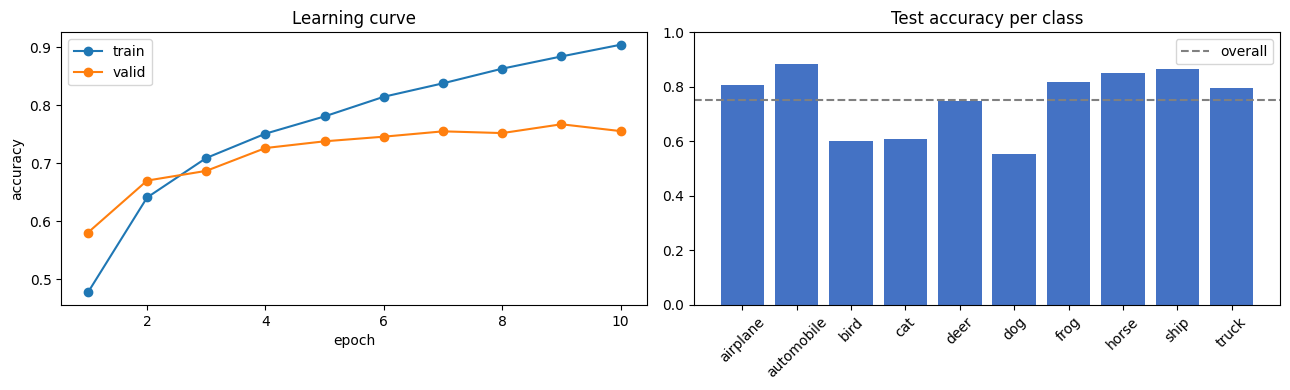

In [ ]:
evaluate(baseline)

## 5) 나만의 모델 만들기
베이스라인은 아주 간단한 모델이라 Test 정확도가 **약 75%** 정도입니다.
목표는 **다른 팀보다 높은 정확도**를 기록하는 것입니다!

- 층을 더 깊게 쌓거나, 데이터 전처리(Data Augumentation)를 추가하거나, 하이퍼파라미터를 조정해 성능을 높여 봅시다.
- 세션에서 깊게 다루지는 않았지만 **Dropout, BatchNorm, L1/L2 규제** 등도 자유롭게 써 보세요.
- 층을 아주 깊게 쌓아 보고 → **과적합이 생기는지 확인**하고 → 규제, 증강으로 극복하며 성능을 올리는 것도 좋은 방향입니다.
  - 과적합 여부는 `evaluate()` 결과의 **과적합 정도 (Train − Test)** 와 **학습 곡선**(train과 valid가 벌어지는지)으로 확인할 수 있습니다.
- 활동 시간에 다룬 **Residual** 을 써 보는 것도 좋은 방법입니다.
    - residual은 nn.Sequence만으로는 구현이 어렵습니다. 아래 코드를 이용해 residual block을 구현해 봅시다.
    ```python
class Residual(nn.Module):
        def __init__(self, block):
            super().__init__()
            self.block = block

        def forward(self, x):
            return self.block(x) + x
    ```

<br>

| 분류 | 예시 |
|---|---|
| **구조 변경** | 채널 수 늘리기, Conv 층 더 쌓기 |
| **BatchNorm** | Conv 바로 뒤에 추가: `nn.Conv2d(...), nn.BatchNorm2d(채널 수), nn.ReLU()` |
| **데이터 전처리 / 증강** | 아래 `my_tf` 에 `transforms.RandomHorizontalFlip()`, `transforms.RandomCrop(32, padding=4)` 추가 |
| **규제** | FC 층 사이에 `nn.Dropout(0.5)` 추가, L2 규제는 `train(..., weight_decay=5e-4)` |
| **학습 설정** | `lr` 변경, `epochs` 늘리기 |

<br>

- 증강은 `ToTensor()` **앞에** 적습니다. `ToTensor()` , `Normalize()` 그래도 내버려 두시면 됩니다.
- 어떤 증강이 있는지는 다음의 문서를 참고해보세요.
    - https://docs.pytorch.org/vision/0.22/transforms.html
- Conv/Pool 구조를 바꾸면 `nn.Linear` 의 입력 크기(`128 * 4 * 4`)도 맞춰서 바꿔야 합니다.
- L1 규제는 `train()` 에 옵션이 없어서, 쓰려면 손실에 가중치 절댓값 합을 직접 더하도록 코드를 고쳐야 합니다. (도전 과제)
    - 코드를 고쳐야 한다는 부담이 있으니, 왜 L1 규제가 필요한지 설명할 수 있을 때 도전해 봅시다.
    - 만약 L1규제를 적용한다면, 기존 train()함수를 복사 붙여넣기 후, 수정해 새로운 train_r1()을 만들어, 규제 적용 전과 적용 후 모델을 함께 비교해보세요

아래는 예시 코드 입니다. 모델 구조나 데이터 전처리를 조정해봅시다.

예를 들면 다음처럼 변형해 볼 수 있습니다.

```python
tf_crop = transforms.Compose([
    # 크롭 데이터 증강
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

def make_deeper() :
    return nn.Sequential( "5층 CNN 구조 정의" )

baseline      = train(make_baseline(), name="Baseline")
baseline_crop = train(make_baseline(), name="Baseline + crop 증강", transform=tf_crop)  # tf_crop 은 직접 정의
deeper        = train(make_deeper(),   name="CNN 5층")                              # make_deeper 는 직접 정의
```
```python
evaluate([baseline, baseline_crop, deeper])
```

#### [model 1] 모델 이름

변경 점
- 데이터 전처리/증강
    - #
- 모델 구조
    - #
- 하이퍼파라미터/규제
    - #
- 기타
    - #
    

In [ ]:
my_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

def make_my_model():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, 3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, 3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Flatten(),
        nn.Linear(128 * 4 * 4, 128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, 10),
    )

my_model = train(make_my_model(), name="My CNN", epochs=EPOCHS, lr=1e-3, weight_decay=0, transform=my_tf)

[My CNN] 학습 시작
  epoch  1: train acc = 43.27% | val acc = 55.84%
  epoch  2: train acc = 56.00% | val acc = 61.90%
  epoch  3: train acc = 61.36% | val acc = 65.96%
  epoch  4: train acc = 64.24% | val acc = 66.86%
  epoch  5: train acc = 66.61% | val acc = 70.60%
  epoch  6: train acc = 68.35% | val acc = 73.04%
  epoch  7: train acc = 69.57% | val acc = 73.50%
  epoch  8: train acc = 71.39% | val acc = 74.72%
  epoch  9: train acc = 71.92% | val acc = 73.92%
  epoch 10: train acc = 73.04% | val acc = 76.12%
  → 학습 완료 (202초)


[My CNN] 단일 평가
  파라미터 수     : 357,258
  Train 정확도    : 73.04%
  Valid 정확도    : 76.12%
  Test  정확도    : 75.16%
  과적합 정도     : -2.12%p  (Train - Test, 클수록 과적합)
  학습 시간       : 202초


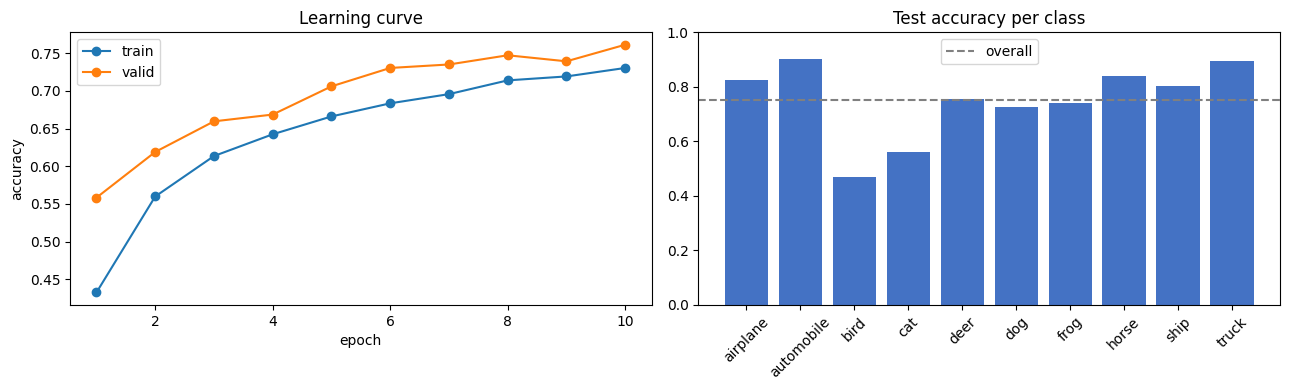

In [ ]:
evaluate(my_model)

#### [model 2] 모델 이름

변경 점
- 데이터 전처리/증강
    - #
- 모델 구조
    - #
- 하이퍼파라미터/규제
    - #
- 기타
    - #

In [22]:
my_tf = transforms.Compose([
    # 여기에 데이터 증강 추가 (예: transforms.RandomHorizontalFlip(),)
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

def make_my_model():
    return nn.Sequential(
        # 현재는 베이스라인과 동일한 구조입니다. 자유롭게 고쳐 보세요!
        nn.Conv2d(3, 32, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
    nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
    nn.Linear(128, 10),
)

my_model = train(make_my_model(), name="My CNN", epochs=EPOCHS, lr=1e-3, weight_decay=0, transform=my_tf)

[My CNN] 학습 시작
  epoch  1: train acc = 46.44% | val acc = 57.16%
  epoch  2: train acc = 62.36% | val acc = 66.20%
  epoch  3: train acc = 69.42% | val acc = 69.54%
  epoch  4: train acc = 73.94% | val acc = 73.38%
  epoch  5: train acc = 76.96% | val acc = 73.36%
  epoch  6: train acc = 80.17% | val acc = 74.60%
  epoch  7: train acc = 82.48% | val acc = 76.60%
  epoch  8: train acc = 84.65% | val acc = 76.24%
  epoch  9: train acc = 87.10% | val acc = 76.46%
  epoch 10: train acc = 88.77% | val acc = 76.90%
  → 학습 완료 (146초)


[My CNN] 단일 평가
  파라미터 수     : 356,810
  Train 정확도    : 88.77%
  Valid 정확도    : 76.90%
  Test  정확도    : 75.01%
  과적합 정도     : 13.76%p  (Train - Test, 클수록 과적합)
  학습 시간       : 146초


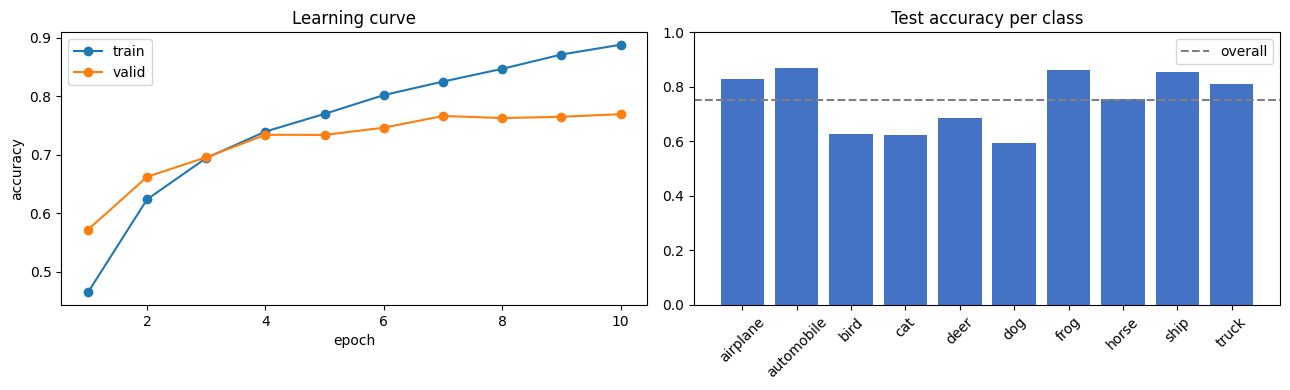

In [23]:
evaluate(my_model)

#### [model 3] 모델 이름

변경 점
- 데이터 전처리/증강
    - #
- 모델 구조
    - #
- 하이퍼파라미터/규제
    - #
- 기타
    - #

In [ ]:
my_tf = transforms.Compose([
    # 여기에 데이터 증강 추가 (예: transforms.RandomHorizontalFlip(),)
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

def make_my_model():
    return nn.Sequential(
        # 현재는 베이스라인과 동일한 구조입니다. 자유롭게 고쳐 보세요!
        nn.Conv2d(3, 32, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
    nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
    nn.Linear(128, 10),
)

my_model = train(make_my_model(), name="My CNN", epochs=EPOCHS, lr=1e-3, weight_decay=0, transform=my_tf)

In [ ]:
evaluate(my_model)

### [최종] 전체 모델 성능 평가

In [ ]:
# 여러 모델을 한번에 비교하기 위해선, 모델 학습 후 아래처럼 리스트에 넣어 평가합니다.
evaluate([baseline, my_model, ])